In [4]:
import scanpy as sc
adata = sc.read_h5ad('data_bio/covid_portal.h5ad', backed='r')
print(adata)
print(adata.obs['full_clustering'].value_counts())

AnnData object with n_obs × n_vars = 697612 × 31279 backed at 'data_bio/covid_portal.h5ad'
    obs: 'sample_id', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'Resample', 'Collection_Day', 'Sex', 'Age', 'Swab_result', 'Status', 'Smoker', 'Status_on_day_collection', 'Status_on_day_collection_summary', 'Days_from_onset', 'Site', 'time_after_LPS', 'Worst_Clinical_Status', 'Outcome', 'initial_clustering', 'full_clustering'
    var: 'feature_types'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
full_clustering
NK_16hi                  83874
CD14_mono                75528
CD83_CD14_mono           69832
CD4.Naive                63141
CD8.TE                   53560
CD4.CM                   50022
B_naive                  43524
CD8.Naive                31256
NK_56hi                  26858
gdT                      20631
CD16_mono                19993
CD8.EM                   18974
CD4.IL22                 18409
Platelets                15073
CD4.Tfh  

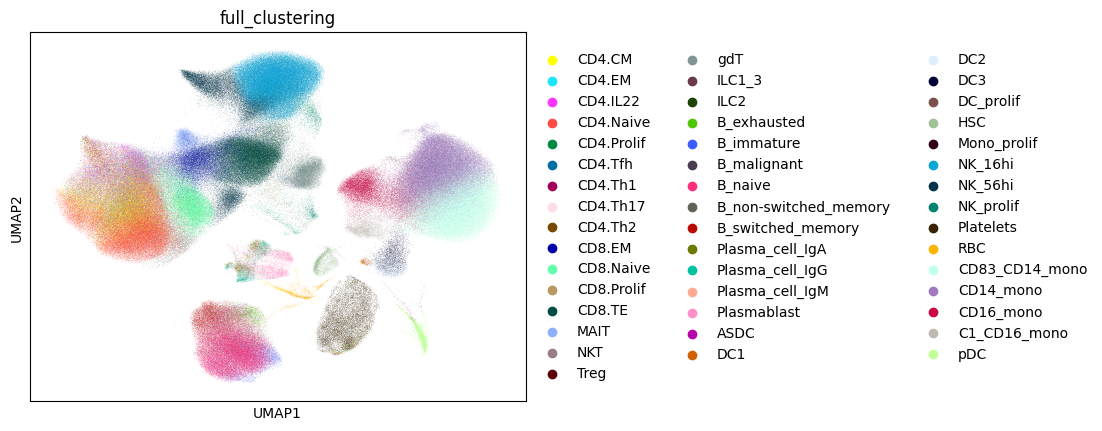

In [5]:
sc.pl.umap(adata, color = ['full_clustering'])

In [6]:
import scanpy as sc
import numpy as np

obs = adata.obs

In [ ]:
mono_labels = ['CD14_mono', 'CD83_CD14_mono', 'CD16_mono', 'C1_CD16_mono', 'Mono_prolif']
mono_mask = obs['full_clustering'].isin(mono_labels)
mono_indices = np.where(mono_mask)[0]
adata_mono = adata[mono_indices].to_memory()
adata_mono.write_h5ad('data_bio/covid_mono_only.h5ad')

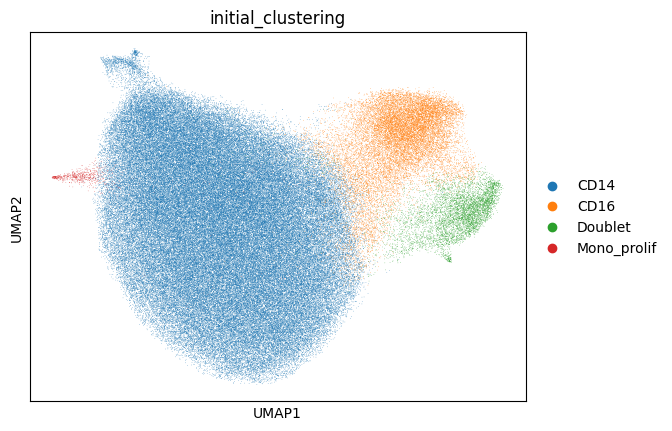

In [ ]:
sc.pp.neighbors(adata_mono, use_rep='X_pca_harmony', n_neighbors=15)
sc.tl.umap(adata_mono, min_dist=0.3)
sc.pl.umap(adata_mono, color=['initial_clustering'], wspace=0.4)

In [10]:
import scanpy as sc
import numpy as np
import scipy 

In [14]:

adata_mono = sc.read_h5ad('data_bio/covid_mono_only.h5ad')
sc.pp.neighbors(adata_mono, use_rep='X_pca_harmony', n_neighbors=15)

In [15]:
latent_space = adata_mono.obsm['X_pca_harmony']
start_cluster = 'CD14_mono'
cluster_mask = adata_mono.obs['full_clustering'] == start_cluster

cluster_coords = latent_space[cluster_mask]
centroid = np.mean(cluster_coords, axis=0)
distances = scipy.spatial.distance.cdist(cluster_coords, [centroid], metric='euclidean').flatten()

closest_cell_idx_in_cluster = np.argmin(distances)
global_indices = np.where(cluster_mask)[0]
root_idx = global_indices[closest_cell_idx_in_cluster]

adata_mono.uns['iroot'] = root_idx

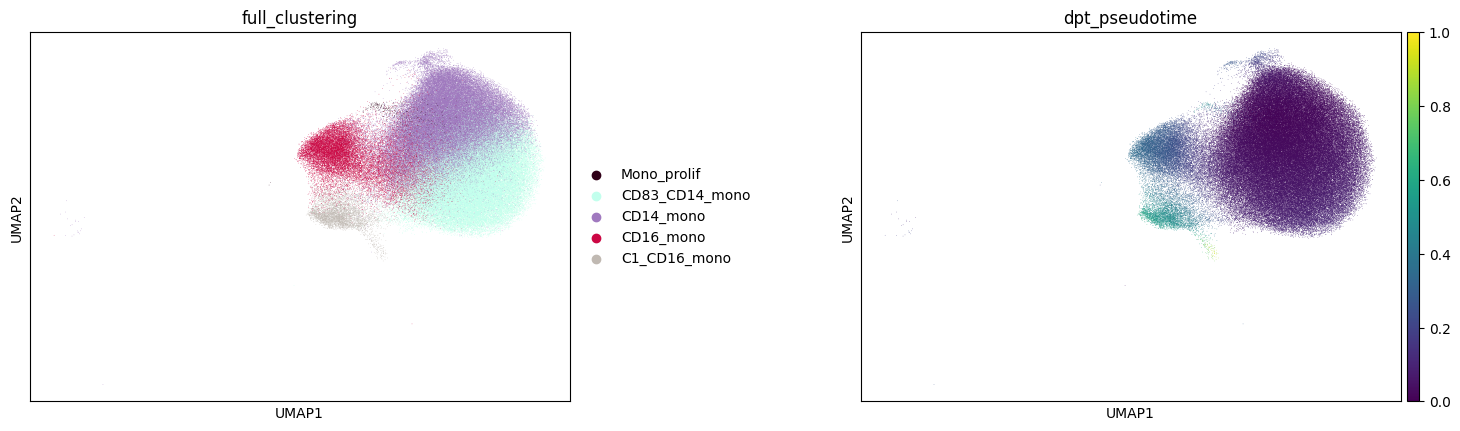

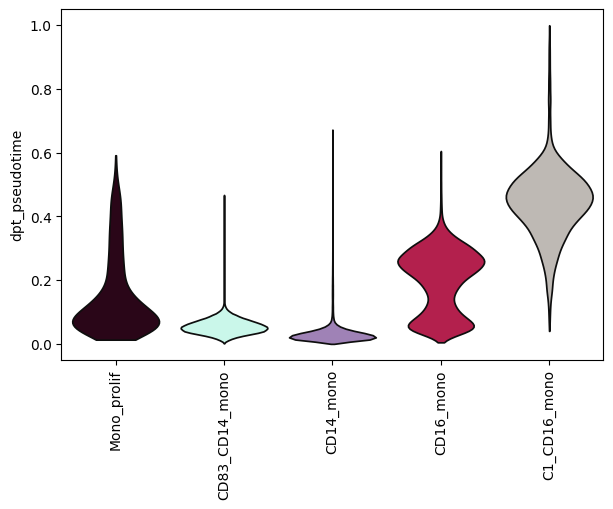

In [16]:
sc.tl.dpt(adata_mono)

sc.pl.umap(adata_mono, color=['full_clustering', 'dpt_pseudotime'], wspace=0.4, color_map='viridis')
sc.pl.violin(adata_mono, keys='dpt_pseudotime', groupby='full_clustering', rotation=90, stripplot=False)

In [ ]:
import numpy as np
import pyslingshot
import pandas as pd
import scanpy as sc
from ggplot2_py import ggplot, aes, geom_point, theme_bw, scale_color_gradientn, labs

np.random.seed(42)
subset_indices = np.random.choice(adata_mono.n_obs, size=15000, replace=False)
adata_sub = adata_mono[subset_indices].copy()

X_sub = adata_sub.obsm['X_pca_harmony']
labels_sub = adata_sub.obs['full_clustering'].astype(str).values

sr = pyslingshot.slingshot(X_sub, labels_sub, start_cluster='CD14_mono')

adata_mono.obs['slingshot_pt'] = np.nan
adata_mono.obs.iloc[subset_indices, adata_mono.obs.columns.get_loc('slingshot_pt')] = sr.pseudotime[:, 0]

df_plot = pd.DataFrame({
    'UMAP1': adata_sub.obsm['X_umap'][:, 0],
    'UMAP2': adata_sub.obsm['X_umap'][:, 1],
    'Pseudotime': sr.pseudotime[:, 0]
})

p = (ggplot(df_plot, aes(x='UMAP1', y='UMAP2', color='Pseudotime'))
     + geom_point(size=0.5, alpha=0.6)
     + scale_color_gradientn(colors=["#440154", "#3E4A89", "#26828E", "#35B779", "#FDE725"])
     + labs(title='Slingshot Pseudotime (Subsampled)', x='UMAP1', y='UMAP2')
     + theme_bw())


In [21]:
from ggplot2_py import ggsave
ggsave("slingshot_plot.png", plot=p, width=8, height=6, dpi=150)

Saving 8 x 6 in image to slingshot_plot.png


'slingshot_plot.png'

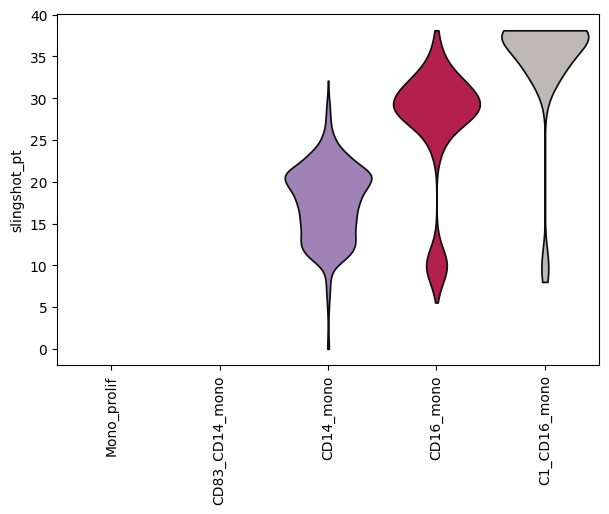

In [23]:
adata_sub.obs['slingshot_pt'] = sr.pseudotime[:, 0]

adata_mono.obs['slingshot_pt'] = np.nan
adata_mono.obs.iloc[subset_indices, adata_mono.obs.columns.get_loc('slingshot_pt')] = sr.pseudotime[:, 0]

adata_sub.write_h5ad('data_bio/covid_mono_sub_slingshot.h5ad')
adata_mono.write_h5ad('data_bio/covid_mono_only_slingshot.h5ad')

sc.pl.violin(adata_sub, keys='slingshot_pt', groupby='full_clustering', rotation=90, stripplot=False)

In [2]:
import pandas as pd
import scanpy as sc
adata_mono = sc.read_h5ad('../data_bio/covid_portal_with_raw.h5ad', backed = 'r')
#harmony_df = pd.DataFrame(adata_mono.obsm['X_pca_harmony'])
#harmony_df.to_csv("harmony_coords.csv", index=False)

#labels_df = pd.DataFrame({'full_clustering': adata_mono.obs['full_clustering'].values})
#labels_df.to_csv("cluster_labels.csv", index=False)

In [3]:

umap_df = pd.DataFrame(adata_mono.obsm['X_umap'], columns=['UMAP1', 'UMAP2'])
umap_df.to_csv("../data_bio/umap_coords.csv", index=False)